# Disfluency-Preserving ASR for Dementia Speech — Ablation Study

**Author:** Tuan Linh Phan (SCIPER 409551)  ·  Team *Lord of the Strings*  ·  CS-552 Open Project (Final Submission)

We fine-tune **Qwen2-Audio-7B-Instruct** with **LoRA** to transcribe DementiaBank (Pitt Corpus) speech
while *preserving* the clinically relevant disfluencies that standard ASR strips out — fillers
(`[uh]`, `[um]`), pauses (`[short/medium/long-pause]`), `[unclear-speech]`, `[laughter]`, `[non-verbal]`.
These disfluencies are the biomarkers used in dementia screening.


## What this notebook contains
1. **Dataset analysis** — corpus size, audio durations, and the disfluency-token distribution (train/test).
2. **Prompted baselines** — zero-shot / few-shot Qwen2-Audio with no fine-tuning (the floor to beat).
3. **Modeling** — the v1→v4 ladder, the focal/CTC variants, the v5 acoustic-VAD CTC, and the winning
   synthetic-data + focal recipe (my main contribution).
4. **Conclusions.**

## Headline result (test set, 168 clips, 8-bracket vocab — see §3 for the apples-to-apples comparison)

| Model | WER ↓ | Disfl. count F1 ↑ | order-aware F1 ↑ |
|---|---|---|---|
| Zero-shot Qwen2-Audio (no adapter) | 0.54 | ~0.0 | 0.0 |
| **synth+focal — synthetic data + focal-on-rare (§3.4) ← best overall** | **0.334** | **0.572** | **0.422** |
| v2 — LoRA + masked embeddings (16 ep), best of the v1→v4 ladder | 0.376 | 0.520 | 0.369 |
| v3 — v2 + frequency-tiered focal loss (γ=2) | 0.401 | 0.537 | 0.363 |
| v4 — v3 + auxiliary CTC head (α=0.3) | 0.444 | 0.494 | 0.325 |

**TL;DR.** Plain LoRA with masked disfluency-token embeddings (**v2**) is the best of the v1→v4 ladder; the **overall best model is synthetic data + focal-on-rare** (§3.4), which adds synthetic training data and beats v2 on every headline metric (WER 0.334, order-aware F1 0.422). **Focal loss (v3)** trades aggregate precision for large **recall gains on the rare tail** (`[non-verbal]`, `[long-pause]`) — useful only if rare-bracket recall is what the clinical task weights. The auxiliary CTC head (v4) did
**not** help and slightly hurt — the made-continuous MFA alignments make the CTC target echo the transcript
rather than supply independent acoustic signal (**CTC**/**MFA** are explained in §3.3.1). Full reasoning and caveats below.


## My contribution

This notebook is my individual contribution to the project. I designed and ran the **iterative ablation ladder (v1 → v5)** that isolates *which* design choices actually recover disfluencies, and I wrote all of the dataset analysis, prompted-baseline scoring, and apples-to-apples re-scoring below. Concretely, I contributed:

- **The v1 → v4 loss/head ladder:** masked-embedding LoRA (v2), frequency-tiered focal loss (v3), and the auxiliary CTC head (v4).
- **The data-artifact diagnosis (v5):** I traced the CTC failure to the *stitched 0.6 s silence* between turns in each clip, and rebuilt the CTC labels from an acoustic VAD.
- **Focal-on-rare loss for the team's best model:** layered on a teammate's synthetic-data recipe, this produced our **best overall model** (WER **0.334**, order-aware F1 **0.422**).

## What worked, and what did not

| Change | Verdict | Why |
|---|---|---|
| Masked-embedding LoRA (v2) | **Worked** | fixed v1's special-token over-emission (3.37× → 0.53×); best of the v1→v4 ladder |
| Focal-on-rare loss | **Worked, in context** | recovers rare-token recall; nets an aggregate win only once layered on the synthetic-data recipe (a precision lever there) |
| Auxiliary CTC, transcript labels (v4) | **Did not work** | labels echoed the transcript (stitched-silence artifact), so the side-task added no new acoustic signal |
| Auxiliary CTC, acoustic-VAD labels (v5) | **Partially** | reversed v4's regression (best aggregate order-aware F1 in the study) but the binary pause vocab caps the clinical pause metric |
| CrisperWhisper encoder init | **Hurt** | diverged on real test during the synthetic-only phase; dropped |

The sections below walk through each of these in order, with the numbers and the reasoning behind every verdict.


## Key terms
- **ASR** — Automatic Speech Recognition (speech → text). **Disfluencies** are the `[uh]`, `[short/medium/long-pause]`, `[unclear-speech]`, `[laughter]`, `[non-verbal]` markers ordinary ASR deletes. We add them as **8 special tokens** and *want* the model to keep them — they are the dementia biomarkers.
- **LoRA** — Low-Rank Adaptation: parameter-efficient fine-tuning that trains small added low-rank matrices (rank `r`) instead of the whole model. *"LoRA footprint"* = which modules get these adapters.
- **WER ↓** — Word Error Rate: edit distance of the predicted transcript to the reference (lower = better transcription). $\mathrm{WER}=\dfrac{S+D+I}{N}$ — substitutions $S$, deletions $D$, insertions $I$, over $N$ reference words.
- **count F1 ↑** — does the model emit the *right number* of each disfluency token? Counting matches by token multiplicity (ignoring position): $P=\dfrac{TP}{TP+FP}$, $R=\dfrac{TP}{TP+FN}$, $F_1=\dfrac{2PR}{P+R}$.
- **order-aware F1 ↑** — stricter: a disfluency counts only if it lands in the *right place* (the prediction is edit-aligned to the reference first) — then the same $F_1=\dfrac{2PR}{P+R}$, but a $TP$ is credited only where the aligned prediction matches. This is our headline disfluency metric. Also reported **pause-only** (the clinical target) and as a **hallucination rate** $=\dfrac{FP}{TP+FP}=1-P$ (disfluencies emitted that aren't in the reference).
- **focal loss** — a loss that **down-weights easy, frequent tokens** so training focuses on the hard, rare ones.
- **CTC head (v4)** — an **auxiliary** output bolted onto the audio model that labels each short slice of audio (a *frame*) as speech / a specific pause / filler / etc. — a classic speech-recognition objective. It is a *side* signal meant to teach the model where pauses are; we still read only the text output. Full mechanism, and why it backfired, in **§3.3.1**.
- **VAD (Voice Activity Detection)** — deciding, from the **audio signal alone** (no transcript), which moments are speech vs silence. v5 uses a VAD to locate *real* acoustic pauses, instead of pauses copied from the transcript (see **§3.3.1**).

## 1. Dataset Analysis


In [1]:
# === Setup — just run this notebook top-to-bottom ("Run All"). No manual steps. =====
# Everything this notebook needs is bundled in the repo, so the grader does NOT
# have to install, build, or fetch anything by hand:
#   - the project package source  -> ../AudioLLM-D/src  (added to sys.path below; no build)
#   - all data + model predictions -> ./nathan          (copied in; no /scratch access needed)
# No third-party ML libraries are needed: all metrics are precomputed (nathan/precomputed_results.json).
# The only auto-step is installing pandas/matplotlib for the tables and plots if they are missing.
import importlib.util
import subprocess
import sys
from pathlib import Path

# 1) Make the project package importable WITHOUT building/installing it.
PKG_SRC = (Path("..") / "AudioLLM-D" / "src").resolve()
if not (PKG_SRC / "audiollm_d").is_dir():
    raise FileNotFoundError(
        f"Expected the project package at {PKG_SRC}. "
        "Run this notebook from the repo's notebooks/ directory."
    )
if str(PKG_SRC) not in sys.path:
    sys.path.insert(0, str(PKG_SRC))

# 2) Ensure the lightweight runtime deps used below are present (install only if missing).
for module, pip_name in [("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

import audiollm_d
print(f"audiollm_d {audiollm_d.__version__} ready (from ../AudioLLM-D/src) — no build needed")

audiollm_d 0.1.0 ready (from ../AudioLLM-D/src) — no build needed


In [2]:
from __future__ import annotations

import json
import re
from pathlib import Path

import pandas as pd

from audiollm_d.chat_parser import _CHAT_TOKEN_MAP

In [3]:
# All data lives in the self-contained `nathan/` folder next to this notebook.
DATA_ROOT = Path("nathan")
SPLITS = ["train", "test"]

split_manifest_paths = {split: DATA_ROOT / f"dataset_manifest_{split}.jsonl" for split in SPLITS}

# Audio durations are precomputed (keyed by clip_id) so the duration analysis below
# runs without shipping the 1.5 GB of raw .wav audio.
AUDIO_DURATIONS = json.loads((DATA_ROOT / "audio_durations.json").read_text())

status_df = pd.DataFrame(
    {
        "split": SPLITS,
        "manifest_path": [str(split_manifest_paths[s]) for s in SPLITS],
        "manifest_exists": [split_manifest_paths[s].exists() for s in SPLITS],
    }
)
display(status_df)

if not status_df["manifest_exists"].all():
    missing = status_df.loc[~status_df["manifest_exists"], "manifest_path"].tolist()
    raise FileNotFoundError(f"Missing manifests: {missing}")

,split,manifest_path,manifest_exists
0,train,nathan/dataset_manifest_train.jsonl,True
1,test,nathan/dataset_manifest_test.jsonl,True


In [4]:
def read_jsonl(path: Path) -> list[dict]:
    rows: list[dict] = []
    with path.open("r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows


def compile_token_pattern(token: str) -> re.Pattern[str]:
    # Count token as a standalone lexical unit, allowing punctuation around it.
    # This avoids under-counting forms like "uh," or "[short-pause]."
    return re.compile(rf"(?<![A-Za-z0-9_]){re.escape(token)}(?![A-Za-z0-9_])")


source_tokens = list(_CHAT_TOKEN_MAP.keys())
mapped_tokens = sorted(set(_CHAT_TOKEN_MAP.values()))
source_token_patterns = {tok: compile_token_pattern(tok) for tok in source_tokens}
mapped_token_patterns = {tok: compile_token_pattern(tok) for tok in mapped_tokens}
map_sub_pattern = re.compile(
    r"(?<![A-Za-z0-9_])("
    + "|".join(re.escape(token) for token in sorted(source_tokens, key=len, reverse=True))
    + r")(?![A-Za-z0-9_])"
)


def apply_chat_map(text: str) -> str:
    return map_sub_pattern.sub(lambda m: _CHAT_TOKEN_MAP[m.group(1)], str(text))

In [5]:
split_records: dict[str, list[dict]] = {
    split: read_jsonl(path) for split, path in split_manifest_paths.items()
}

# Audio analysis for BOTH splits.
audio_summary_rows = []
for split, rows in split_records.items():
    durations = [AUDIO_DURATIONS[r["clip_id"]] for r in rows]
    s = pd.Series(durations, dtype=float)
    audio_summary_rows.append(
        {
            "split": split,
            "num_clips": int(s.size),
            "total_seconds": float(s.sum()),
            "total_hours": float(s.sum() / 3600.0),
            "mean_seconds": float(s.mean()),
            "median_seconds": float(s.median()),
            "min_seconds": float(s.min()),
            "max_seconds": float(s.max()),
        }
    )

audio_summary_df = pd.DataFrame(audio_summary_rows).sort_values("split").reset_index(drop=True)

display(audio_summary_df)

,split,num_clips,total_seconds,total_hours,mean_seconds,median_seconds,min_seconds,max_seconds
0,test,168,3843.650029,1.067681,22.878869,26.35449,0.710998,29.96
1,train,658,15831.826906,4.397730,24.060527,26.57551,0.684989,30.00


In [6]:
# Text analysis for BOTH splits.
# 1) Initial distribution: CHAT-map source tokens counted on the raw transcripts. The raw
#    transcripts are private, so only precomputed aggregate counts are shipped
#    (nathan/raw_source_token_distribution.json) — no transcript text is included.
# 2) Post-map distribution: mapped tokens after applying the same map on the manifest text.

raw_dist = json.loads((DATA_ROOT / "raw_source_token_distribution.json").read_text())
coverage_df = pd.DataFrame(raw_dist["coverage"]).sort_values("split").reset_index(drop=True)

initial_rows = []
for split in SPLITS:
    for token, count in raw_dist["initial_counts"][split].items():
        initial_rows.append({"split": split, "source_token": token, "count": int(count)})

mapped_rows = []
for split, rows in split_records.items():
    mapped_texts = [apply_chat_map(str(r.get("text", ""))) for r in rows]
    for token, pattern in mapped_token_patterns.items():
        count = sum(len(pattern.findall(text)) for text in mapped_texts)
        mapped_rows.append({"split": split, "mapped_token": token, "count": int(count)})

initial_long_df = pd.DataFrame(initial_rows)
initial_dist_df = (
    initial_long_df.pivot(index="source_token", columns="split", values="count")
    .fillna(0).astype(int)
    .rename(columns={"train": "train_count", "test": "test_count"})
    .reset_index()
)
initial_dist_df["total_count"] = initial_dist_df["train_count"] + initial_dist_df["test_count"]
initial_dist_df = initial_dist_df.sort_values(["total_count", "source_token"], ascending=[False, True]).reset_index(drop=True)

mapped_long_df = pd.DataFrame(mapped_rows)
mapped_dist_df = (
    mapped_long_df.pivot(index="mapped_token", columns="split", values="count")
    .fillna(0).astype(int)
    .rename(columns={"train": "train_count", "test": "test_count"})
    .reset_index()
)
excluded_mapped_tokens = {"like", "you know"}
mapped_dist_df = mapped_dist_df[~mapped_dist_df["mapped_token"].isin(excluded_mapped_tokens)].copy()
mapped_dist_df["total_count"] = mapped_dist_df["train_count"] + mapped_dist_df["test_count"]
mapped_dist_df = mapped_dist_df.sort_values(["total_count", "mapped_token"], ascending=[False, True]).reset_index(drop=True)

print("Raw transcript coverage for initial distribution")
display(coverage_df)
print("Initial distribution over CHAT map source tokens from raw transcripts (train vs test)")
display(initial_dist_df)
print("Distribution of mapped/new tokens after applying CHAT token map on the manifest text (train vs test)")
display(mapped_dist_df)

Raw transcript coverage for initial distribution


,split,manifest_clips,unique_source_ids,raw_cha_found,raw_cha_missing,raw_coverage
0,test,168,51,51,0,1.0
1,train,658,154,154,0,1.0


Initial distribution over CHAT map source tokens from raw transcripts (train vs test)


split,source_token,test_count,train_count,total_count
0,&-uh,125,877,1002
1,(.),109,356,465
2,&-um,74,384,458
3,+.,98,224,322
4,+..,98,223,321
5,+...,97,215,312
6,&uh,44,267,311
7,xxx,49,215,264
8,(..),55,135,190
9,&=laughs,46,103,149


Distribution of mapped/new tokens after applying CHAT token map on the manifest text (train vs test)


split,mapped_token,test_count,train_count,total_count
0,[uh],164,1127,1291
1,[unclear-speech],132,945,1077
2,[um],79,410,489
3,[short-pause],105,354,459
4,[long-pause],96,233,329
5,[medium-pause],53,143,196
6,[laughter],40,93,133
7,[non-verbal],24,87,111


## Disfluency token percentage in corpus

In [7]:
disfluency_tokens = [
    "[uh]",
    "[um]",
    "[short-pause]",
    "[medium-pause]",
    "[long-pause]",
    "[unclear-speech]",
    "[laughter]",
    "[non-verbal]",
]

disfluency_patterns = {tok: compile_token_pattern(tok) for tok in disfluency_tokens}

split_text_stats = []
per_token_rows = []
combined_texts: list[str] = []

for split, rows in split_records.items():
    mapped_texts = [apply_chat_map(str(r.get("text", ""))) for r in rows]
    combined_texts.extend(mapped_texts)

    total_tokens = sum(len(text.split()) for text in mapped_texts)
    token_counts = {
        tok: sum(len(disfluency_patterns[tok].findall(text)) for text in mapped_texts)
        for tok in disfluency_tokens
    }
    total_disfluency_tokens = sum(token_counts.values())

    split_text_stats.append(
        {
            "split": split,
            "num_samples": len(rows),
            "total_tokens": total_tokens,
            "total_disfluency_tokens": total_disfluency_tokens,
            "disfluency_token_percentage": (100.0 * total_disfluency_tokens / total_tokens) if total_tokens else 0.0,
        }
    )

    for tok in disfluency_tokens:
        count = token_counts[tok]
        per_token_rows.append(
            {
                "split": split,
                "token": tok,
                "count": count,
                "pct_of_all_tokens": (100.0 * count / total_tokens) if total_tokens else 0.0,
                "pct_within_disfluency_tokens": (
                    100.0 * count / total_disfluency_tokens
                )
                if total_disfluency_tokens
                else 0.0,
            }
        )

# Add combined (train + test)
combined_total_tokens = sum(len(text.split()) for text in combined_texts)
combined_counts = {
    tok: sum(len(disfluency_patterns[tok].findall(text)) for text in combined_texts)
    for tok in disfluency_tokens
}
combined_total_disfluency = sum(combined_counts.values())

split_text_stats.append(
    {
        "split": "all",
        "num_samples": len(combined_texts),
        "total_tokens": combined_total_tokens,
        "total_disfluency_tokens": combined_total_disfluency,
        "disfluency_token_percentage": (
            100.0 * combined_total_disfluency / combined_total_tokens
        )
        if combined_total_tokens
        else 0.0,
    }
)

for tok in disfluency_tokens:
    count = combined_counts[tok]
    per_token_rows.append(
        {
            "split": "all",
            "token": tok,
            "count": count,
            "pct_of_all_tokens": (100.0 * count / combined_total_tokens) if combined_total_tokens else 0.0,
            "pct_within_disfluency_tokens": (100.0 * count / combined_total_disfluency)
            if combined_total_disfluency
            else 0.0,
        }
    )

corpus_disfluency_df = pd.DataFrame(split_text_stats)
per_token_disfluency_df = pd.DataFrame(per_token_rows)

print("Overall disfluency-token percentage by split")
display(corpus_disfluency_df.style.format({"disfluency_token_percentage": "{:.2f}%"}))

print("Per-token distribution (percentage of corpus and of disfluency tokens)")
display(
    per_token_disfluency_df.sort_values(["split", "token"]).reset_index(drop=True).style.format(
        {
            "pct_of_all_tokens": "{:.3f}%",
            "pct_within_disfluency_tokens": "{:.2f}%",
        }
    )
)

Overall disfluency-token percentage by split


,split,num_samples,total_tokens,total_disfluency_tokens,disfluency_token_percentage
0,train,658,32461,3392,10.45%
1,test,168,6913,693,10.02%
2,all,826,39374,4085,10.37%


Per-token distribution (percentage of corpus and of disfluency tokens)


,split,token,count,pct_of_all_tokens,pct_within_disfluency_tokens
0,all,[laughter],133,0.338%,3.26%
1,all,[long-pause],329,0.836%,8.05%
2,all,[medium-pause],196,0.498%,4.80%
3,all,[non-verbal],111,0.282%,2.72%
4,all,[short-pause],459,1.166%,11.24%
5,all,[uh],1291,3.279%,31.60%
6,all,[um],489,1.242%,11.97%
7,all,[unclear-speech],1077,2.735%,26.36%
8,test,[laughter],40,0.579%,5.77%
9,test,[long-pause],96,1.389%,13.85%


## 2. Prompted Baselines — can Qwen2-Audio do this *without* fine-tuning?

Before any training, we check whether a **prompted** Qwen2-Audio-7B-Instruct already produces the disfluency
tokens, under two regimes: **zero-shot** (instruction only) and **few-shot** (instruction + in-context
examples). These set the **floor** that the fine-tuned models in §3 must beat. Numbers are the team's
prompted-baseline runs, scored with the same `audiollm_d` disfluency metrics used throughout.

In [8]:
# --- Prompted baselines: zero-shot vs few-shot Qwen2-Audio, no fine-tuning ---
BASE = DATA_ROOT  # zero/few-shot baseline metric JSONs copied into nathan/
zero_shot_metrics = json.loads((BASE / "zero_shot_metrics_new2.json").read_text())
few_shot_metrics  = json.loads((BASE / "few_shot_metrics_new2.json").read_text())

rows = []
for name, d in [("Zero-shot (prompted)", zero_shot_metrics), ("Few-shot (prompted)", few_shot_metrics)]:
    dm = d["disfluency_metrics"]
    rows.append({
        "Scenario": name, "WER": d["wer"],
        "Disfl. Precision": dm["disfluency_token_precision"],
        "Disfl. Recall": dm["disfluency_token_recall"],
        "Disfl. F1 (count)": dm["disfluency_token_f1"],
        "order-aware F1": dm["disfluency_token_order_f1"],
    })
baseline_df = pd.DataFrame(rows)
print("Prompted baselines (no fine-tuning) — test split")
display(baseline_df.style.format({c: "{:.4f}" for c in baseline_df.columns if c != "Scenario"}).hide(axis="index"))

# Per-token disfluency F1 floor (zero-shot vs few-shot).
tokens = sorted(set(zero_shot_metrics["disfluency_metrics"]["per_token_stats"])
                | set(few_shot_metrics["disfluency_metrics"]["per_token_stats"]))
ptrows = [{
    "Token": t,
    "Zero-shot F1": zero_shot_metrics["disfluency_metrics"]["per_token_stats"].get(t, {}).get("f1", 0.0),
    "Few-shot F1":  few_shot_metrics["disfluency_metrics"]["per_token_stats"].get(t, {}).get("f1", 0.0),
} for t in tokens]
print("Per-token disfluency F1 — the prompted floor")
display(pd.DataFrame(ptrows).style.format({"Zero-shot F1": "{:.4f}", "Few-shot F1": "{:.4f}"}).hide(axis="index"))

Prompted baselines (no fine-tuning) — test split


Scenario,WER,Disfl. Precision,Disfl. Recall,Disfl. F1 (count),order-aware F1
Zero-shot (prompted),0.5396,0.3871,0.0173,0.0331,0.0119
Few-shot (prompted),0.6634,0.0436,0.0216,0.0289,0.0101


Per-token disfluency F1 — the prompted floor


Token,Zero-shot F1,Few-shot F1
[laughter],0.1111,0.0690
[long-pause],0.0594,0.0138
[medium-pause],0.0357,0.0000
[non-verbal],0.0000,0.0000
[short-pause],0.0727,0.0585
[uh],0.0000,0.0121
[um],0.0000,0.0221
[unclear-speech],0.0149,0.0420


**Takeaway — prompting is not enough.** Zero-shot Qwen2-Audio reaches WER ≈0.54 but **almost never emits the
disfluency tokens** (recall 0.017, count-F1 0.033); few-shot prompting is *worse* on WER (0.66) and no better
on disfluencies (count-F1 0.029). The clinically relevant markers — pauses, fillers, laughter — are
essentially absent without training. Closing this gap is exactly what **§3** does: fine-tuning lifts
disfluency count-F1 from ≈0 to **0.52–0.57** and WER to **0.33**.

## 3. Modeling — the v1 → v4 Ablation Ladder

**Base model.** Qwen2-Audio-7B-Instruct. The 8 disfluency tokens are added to the tokenizer; their input
embeddings + LM-head rows are trained, and (from v2 on) gradients to the rest of the embedding matrix are
**masked** so only the 8 new rows move.

| Ver | Idea | Encoder LoRA | LM LoRA | Embeddings | Loss |
|---|---|---|---|---|---|
| **v1** | first pass | all 32 layers, q/k/v/o, r16 | q/k/v/o + MLP | full vocab trainable (no mask) | weighted CE (×2) |
| **v2** | **masked embeddings + targeted LoRA** | layers 24–31, q/v, r8 | q/v, r16 | **masked to the 8 new rows** | uniform CE |
| **v3** | **frequency-tiered focal loss** | = v2 | = v2 | = v2 | **tiered focal, γ=2** (rare brackets α=3.0, fillers 1.5) |
| **v4** | **auxiliary CTC head** | = v3 | = v3 | = v3 | `L_focal + α·L_CTC`, α∈{0.3, 0.5} |

- **v1 → v2:** v1's full-vocab-trainable head *over-emitted* special tokens (3.37× the reference rate).
  Masking the embeddings + shrinking the LoRA footprint fixed this (v2 *under*-emits at 0.53×) and gave a
  large precision jump. v2 trained for **16 epochs** is the strongest model on record.
- **v2 → v3:** focal loss was added to recover **recall** on the rare brackets that v2 under-emits.
- **v3 → v4:** an auxiliary **CTC head** — a per-audio-frame classifier on the encoder (`Linear(1280→8)`, 25 frames/s; CTC defined in §3.3.1) — was added
  to give the encoder a direct, frame-level disfluency signal. The reported metric is always the **LM head's
  text output**; CTC is auxiliary.

### Metrics (recap — see *Key terms* up front)
- **WER** ↓ — overall transcription quality (`jiwer`).
- **Disfluency count F1** ↑ — order-agnostic token-count P/R/F1 over the 8 brackets.
- **order-aware F1** ↑ — Levenshtein-aligns hypothesis↔reference, then scores disfluency matches at
  aligned positions. This is the **headline disfluency metric** (an inserted pause in the wrong place is not
  a true positive). Also reported **pause-only** (the clinical target) and as a **hallucination rate** (disfluencies emitted that aren't in the reference).

All §3 numbers were computed with `audiollm_d.metrics` on the **saved training-time predictions** (batched
greedy decode) at each version's **best epoch**, on the shared **8-bracket** test set — so every row is
apples-to-apples (these reproduce my `report/ablations_tracker.md` numbers exactly). They are **precomputed**
and loaded from `nathan/precomputed_results.json` so this notebook runs standalone.


In [9]:
# --- Results infrastructure: load precomputed metrics (computed offline with audiollm_d.metrics) ---
# Every table in S3 was computed from the saved training-time predictions with the project's own
# audiollm_d.metrics (WER + count-based and order-aware disfluency metrics, plus bootstrap CIs),
# then cached to nathan/precomputed_results.json so this notebook is fully self-contained: no
# prediction files or heavy scoring at runtime. Provenance: nathan/results_manifest.json.
from audiollm_d.special_tokens import DISFLUENCY_TOKENS

PRECOMP = json.loads((DATA_ROOT / "precomputed_results.json").read_text())
print("Disfluency tokens:", DISFLUENCY_TOKENS)
print("Loaded precomputed result tables:", ", ".join(PRECOMP.keys()))

Disfluency tokens: ['[short-pause]', '[medium-pause]', '[long-pause]', '[unclear-speech]', '[laughter]', '[non-verbal]', '[uh]', '[um]']
Loaded precomputed result tables: headline, sweep, per_token_v2_v3, ctc, slice_n, slice, slice_per_token, ci, ctc_loss_curve, curr, jump, traj


In [10]:
# --- Headline comparison: each version at its best epoch (precomputed, 8-bracket 168-clip test) ---
headline_df = pd.DataFrame(PRECOMP["headline"])
fmt = {c: "{:.3f}" for c in headline_df.columns if c != "Model"}
print("Headline comparison — test set (168 clips), best epoch per version")
display(headline_df.style.format(fmt).hide(axis="index"))

Headline comparison — test set (168 clips), best epoch per version


Model,WER,count F1,count-P,count-R,order-aware F1,Pause order-aware F1,Halluc. rate
baseline (no adapter),0.575,0.000,0.000,0.000,0.000,0.000,0.000
v2 LoRA (16ep) — winner,0.376,0.520,0.598,0.460,0.369,0.183,0.402
v3 focal (gamma=2),0.401,0.537,0.591,0.492,0.363,0.201,0.409
v4 CTC (alpha=0.3),0.444,0.494,0.548,0.450,0.325,0.170,0.452
v4 CTC (alpha=0.5),0.471,0.496,0.517,0.476,0.319,0.214,0.483


**Reading the table.**
- **v2 (LoRA, 16 ep) is the best model** on every headline metric: lowest WER (0.376), highest order-aware F1
  (0.369) and the best count-precision. It is the strongest model in the v1→v4 ladder; the synthetic-data + focal recipe (§3.4) later surpasses it.
- **v3 (focal)** has a *higher* count F1 (0.537) than v2 (0.520) because focal lifts recall — but its
  **order-aware F1 is slightly lower** and it hallucinates more. The win is concentrated on the rare
  tail (§3.1), not in aggregate.
- **v4 (CTC)** is worse than both v2 and v3 on WER and order-aware F1 (§3.2).

**Caveats (so the comparison is honest):**
- All four rows use the **8-bracket vocab** (`[uh]`/`[um]` atomic) and **batched greedy decode** at each
  version's best epoch — the one regime in which they are directly comparable.
- **v1** and the original **v2 (4 ep)** were trained on the *old* data split (161/153) with raw-CHAT markers
  (`&-uh`, `(.)`), so they are **not** comparable to the rows above. For the record (from
  `report/ablations_tracker.md`): v1 WER 0.558 / count F1 0.232; v2 (4 ep) WER 0.595 / count F1 0.453. They
  established the *over-emit → mask → under-emit* trajectory that motivated the 16-epoch v2.
- A separate `eval_wer.py` single-sample decode gives marginally different WER (e.g. v2 0.401 vs 0.376); the
  batched numbers here are internally consistent across versions, which is what matters for the ablation.


version,epoch,WER,count F1,order-aware F1,pause order-aware F1
v2 (16ep),2,0.670,0.177,0.119,0.042
v2 (16ep),4,0.396,0.468,0.327,0.174
v2 (16ep),6,0.551,0.288,0.196,0.161
v2 (16ep),8,0.389,0.473,0.362,0.117
v2 (16ep),10,0.394,0.536,0.365,0.242
v2 (16ep),12,0.386,0.518,0.355,0.208
v2 (16ep),14,0.376,0.520,0.369,0.183
v3 focal,2,0.625,0.168,0.110,0.055
v3 focal,4,0.559,0.338,0.282,0.111
v3 focal,6,0.435,0.388,0.252,0.101


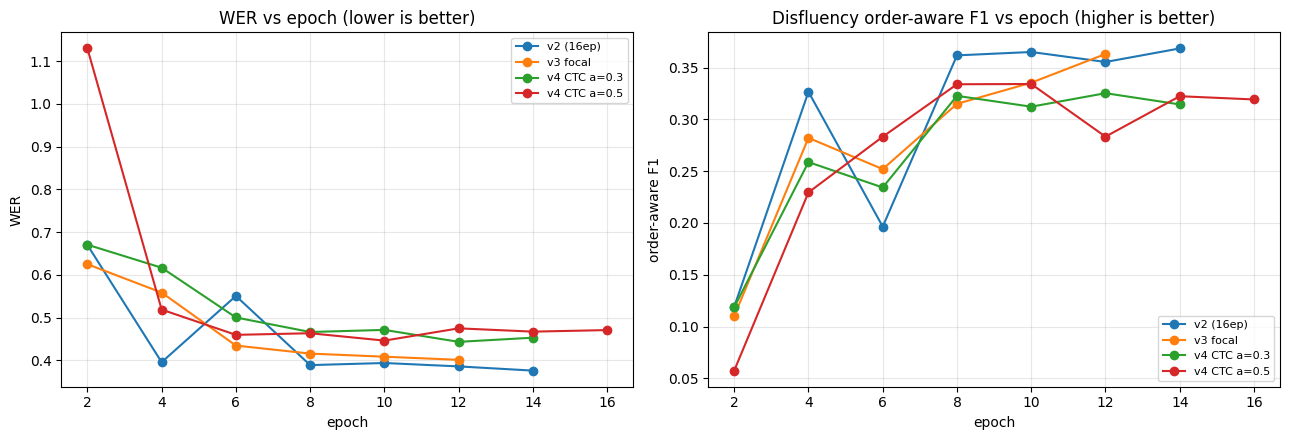

In [11]:
# --- Epoch sweeps: WER / order-aware F1 / count F1 over training, per version (precomputed) ---
sweep_df = pd.DataFrame(PRECOMP["sweep"])
display(sweep_df.style.format({c: "{:.3f}" for c in ["WER", "count F1", "order-aware F1", "pause order-aware F1"]}).hide(axis="index"))

# Plot WER and order-aware F1 vs epoch for all versions.
try:
    import matplotlib.pyplot as plt
    versions = list(dict.fromkeys(sweep_df["version"]))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ver in versions:
        g = sweep_df[sweep_df["version"] == ver]
        axes[0].plot(g["epoch"], g["WER"], marker="o", label=ver)
        axes[1].plot(g["epoch"], g["order-aware F1"], marker="o", label=ver)
    axes[0].set_title("WER vs epoch (lower is better)"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("WER")
    axes[1].set_title("Disfluency order-aware F1 vs epoch (higher is better)"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("order-aware F1")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
except Exception as e:
    print("plot skipped:", e)

### 3.1 Focal loss (v3): a recall-for-precision knob on the rare tail

Frequency-tiered focal loss (γ=2, with larger α on the rarest brackets) was designed to move exactly one
thing: **recall on the rare disfluency tokens** that v2 systematically under-emits. The per-token table
below (v2-16ep ep14 vs v3 ep12, same decode) shows it did precisely that.


In [12]:
# --- Per-token effect of focal loss: v2 (uniform CE) vs v3 (tiered focal) (precomputed) ---
per_token_df = pd.DataFrame(PRECOMP["per_token_v2_v3"])
display(per_token_df.style.format({
    "v2 recall": "{:.3f}", "v3 recall": "{:.3f}", "Δ recall": "{:+.3f}",
    "v2 F1": "{:.3f}", "v3 F1": "{:.3f}", "Δ F1": "{:+.3f}",
}).hide(axis="index"))

Token,ref N,v2 recall,v3 recall,Δ recall,v2 F1,v3 F1,Δ F1
[non-verbal],24,0.125,0.292,+0.167,0.171,0.333,+0.162
[laughter],40,0.175,0.250,+0.075,0.264,0.351,+0.087
[medium-pause],53,0.208,0.208,+0.000,0.265,0.256,-0.009
[um],79,0.759,0.671,-0.089,0.805,0.746,-0.059
[long-pause],96,0.260,0.385,+0.125,0.342,0.477,+0.135
[short-pause],105,0.286,0.381,+0.095,0.385,0.449,+0.065
[unclear-speech],132,0.477,0.485,+0.008,0.450,0.454,+0.004
[uh],164,0.732,0.726,-0.006,0.741,0.726,-0.015


**Takeaway — focal worked as intended on the rare tail, but is not a free win.**
The biggest recall/F1 gains land on the *rarest* tokens — `[non-verbal]` (24 refs) recall roughly triples,
`[long-pause]` and `[short-pause]` recall jump — while the common fillers `[uh]`/`[um]` lose a little. Because
fillers dominate the corpus, v3 over-shifts toward emitting disfluencies (its hallucination rate rises) and
its **aggregate** order-aware F1 ends up slightly *below* v2. So focal is a **recall-for-precision knob
on the long tail**: choose it only if the clinical use case weights rare-bracket recall above overall
transcription fidelity. Otherwise, plain v2 wins.


### 3.2 Auxiliary CTC head (v4): did it help? — No.

v4 adds a **CTC head** — a frame-labeling objective on the post-pooling audio-encoder features (fully defined in §3.3.1) (8 classes: speech, the three pauses,
unclear-speech, laughter, non-verbal, blank) with joint loss `L_focal + α·L_CTC`, swept at α∈{0.3, 0.5}.
The CTC loss **did** converge (from initialization down to ≈1.0 — see the curve in §3.3.1), so the head trained — but the **LM text output** got no better.


In [13]:
# --- CTC verdict: v4 (both alphas) vs the no-CTC bases (v2, v3) (precomputed) ---
ctc_df = pd.DataFrame(PRECOMP["ctc"])
display(ctc_df.style.format({c: "{:.3f}" for c in ctc_df.columns if c != "Model"}).hide(axis="index"))

Model,WER,order-aware F1 (all),order-aware F1 (pause-only),count F1
v2 LoRA (16ep) — winner,0.376,0.369,0.183,0.520
v3 focal (gamma=2),0.401,0.363,0.201,0.537
v4 CTC (alpha=0.3),0.444,0.325,0.170,0.494
v4 CTC (alpha=0.5),0.471,0.319,0.214,0.496


**Verdict — the auxiliary CTC head did not help; it slightly hurt.**
On the apples-to-apples comparison, v4's best (α=0.3, ep12: WER 0.444, order-aware F1 0.325) is **worse than the
no-CTC v2 winner on every headline metric** (WER 0.376, order-aware F1 0.369), and even behind its own base design
v3. Raising the weight to α=0.5 did **not** recover the aggregate loss.

**Why (a real design caveat).** The upstream Montreal-Forced-Aligner alignments were "made-continuous," so
the CTC pause labels largely **echo the transcript's pause tokens** rather than independently-detected
acoustic silence. The CTC objective therefore reinforced structure the LM already had — adding noise and
redundancy instead of new acoustic signal — and dragged on the shared LoRA/LM parameters.

**One narrow bright spot.** α=0.5 concentrates the limited CTC signal onto pauses: its **pause-only order-aware F1
(0.214 at ep16)** is the best pause score on record, above α=0.3 and above v2. So if pause detection were the
sole objective, higher-α CTC is defensible — but on overall transcription it loses. Given both swept α's
underperform in aggregate and the data caveat caps the ceiling, CTC was not pursued further.


### 3.3 v5 — acoustically-grounded CTC labels (fixing v4's data caveat)

§3.2 blamed v4 on the **label source**: the made-continuous MFA pause labels echoed the transcript instead of supplying independent acoustic signal. Inspecting the data confirmed the mechanism concretely — the training clips are **stitched** from participant turns by `build_cd_clips.py`, which inserts a **constant 0.6 s of digital-zero silence** between turns (`audio.py`, `pause_seconds=0.6`). So the only clean "silence" in the audio is a transcript-correlated artifact of fixed width, not a real acoustic pause.

**v5 changes exactly one variable vs v4: the CTC label source.** Stage 0 now runs an **acoustic energy VAD** (Voice Activity Detection — labeling speech vs silence from the audio signal alone, no transcript) **on the waveform** and **excises the 0.6 s synthetic pads** (contiguous *exact*-zero runs — real pauses have a nonzero noise floor), leaving genuine acoustic pauses of variable duration. A Stage-1 gate found those durations don't cleanly separate into short/medium/long, so v5 uses a **binary `{speech, pause}`** CTC vocab. Real acoustic pauses are only reliably recoverable on the clean **ADReSS** third of the merged corpus (the noisy Pitt/PPA clips have breath-filled pauses an energy VAD can't ground), so v5 is trained and evaluated on the **ADReSS clips** (248 train / 66 test, speaker-disjoint).

> ⚠️ **Comparison note.** Because v5 lives on the ADReSS subset, the 168-clip numbers in §3 are **not** comparable to it. The table below reports **every model on the shared 66-clip ADReSS test slice** — same best-epoch checkpoints as §3, same `audiollm_d.metrics` code — so the v5 row is apples-to-apples (precomputed). Full bootstrap 95% CIs and provenance: `AudioLLM-D/reports/v5_adress_comparison.md`; the data-artifact write-up: `AudioLLM-D/docs/v5_finding_stitched_silence.md`.

In [14]:
# --- 3.3 v5: all models re-scored on the shared ADReSS test slice (precomputed) ---
# v5 trains+evaluates on the clean ADReSS subset only, so the 168-clip numbers in S3 are NOT
# comparable. Every model was restricted to the same ADReSS test clips (by clip_id), reusing the
# SAME best-epoch checkpoints and metric code, so the v5 row is apples-to-apples.
slice_df = pd.DataFrame(PRECOMP["slice"])
print(f"All models re-scored on the shared {PRECOMP['slice_n']}-clip ADReSS test slice (speaker-disjoint)")
display(slice_df.style.format({c: "{:.3f}" for c in slice_df.columns if c not in ("Model", "n")}).hide(axis="index"))

# Per-token F1 across all 8 disfluency tokens, on the slice.
slice_token_df = pd.DataFrame(PRECOMP["slice_per_token"])
print("Per-token F1 on the ADReSS slice (the 3 pause tokens are v5's actual target)")
display(slice_token_df.style.format({c: "{:.3f}" for c in slice_token_df.columns if c != "Token"}).hide(axis="index"))

All models re-scored on the shared 66-clip ADReSS test slice (speaker-disjoint)


Model,n,WER,count F1,order-aware F1 (all),order-aware F1 (pause-only)
v2 LoRA (16ep),66,0.379,0.475,0.358,0.111
v3 focal,66,0.424,0.494,0.339,0.120
v4 CTC (a=0.3),66,0.443,0.394,0.309,0.099
v4 CTC (a=0.5),66,0.471,0.491,0.337,0.217
v5 VAD-CTC (binary),66,0.413,0.433,0.370,0.149


Per-token F1 on the ADReSS slice (the 3 pause tokens are v5's actual target)


Token,v2 LoRA (16ep),v3 focal,v4 CTC (a=0.3),v4 CTC (a=0.5),v5 VAD-CTC (binary)
[short-pause],0.412,0.372,0.316,0.440,0.233
[medium-pause],0.167,0.091,0.182,0.250,0.200
[long-pause],0.133,0.316,0.087,0.316,0.125
[unclear-speech],0.163,0.178,0.170,0.302,0.194
[laughter],0.600,0.750,0.133,0.476,0.476
[non-verbal],0.308,0.333,0.267,0.429,0.143
[uh],0.755,0.791,0.747,0.733,0.778
[um],0.667,0.545,0.545,0.571,0.667


#### Why the confidence intervals matter (and how to read them)

The table above is **point estimates** on only **66 test clips** — small enough that one or two lucky/unlucky clips can move a metric by several points. A **bootstrap 95% confidence interval (CI)** measures exactly that fragility:

> resample the 66 clip-level *(reference, prediction)* pairs **with replacement** 1000 times, recompute the metric on each fake "re-drawn" test set, and report the middle 95% of those values — the `[2.5th, 97.5th]` percentile band.

Intuitively, the CI is *the range the score would plausibly take if we had drawn a different sample of 66 clips from the same population.* A wide band = the number is not pinned down; a narrow band = it's stable.

**How to read it:** if two models' CIs **overlap**, the difference between their point estimates is **within sampling noise — you cannot claim one is better.** Only when the intervals **do not overlap** is the difference likely real.

**Why this is essential here, not decoration:** it's the guardrail against over-claiming on a small test set. The cell below shows it bites hard — e.g. v5's order-aware F1 `0.370 [0.286, 0.447]` overlaps the v2 baseline's `0.358 [0.272, 0.443]` almost entirely, and v5's pause F1 `0.149 [0.051, 0.235]` overlaps v4-α0.5's `0.217 [0.092, 0.330]`. So even though v5 *leads on point estimates*, **none of these gaps are statistically established.** The honest takeaway is "promising trend, not a proven win", and the lever to get a real result is **more clean-pause data** (which shrinks the CIs), not more tuning. The same 1000-resample CIs back every comparison in `AudioLLM-D/reports/v5_adress_comparison.md`.

In [15]:
# --- 3.3 (cont.) Bootstrap 95% confidence intervals on the ADReSS slice (precomputed) ---
# Point estimates on 66 clips are noisy. Each metric's CI comes from resampling the 66 clip pairs
# WITH REPLACEMENT 1000x (seed=0) and taking the 2.5th-97.5th percentile band. Overlapping bands
# => the gap is within sampling noise.
ci_df = pd.DataFrame(PRECOMP["ci"])
print("Bootstrap 95% CIs on the 66-clip ADReSS slice (1000 resamples, seed=0)")
display(ci_df.style.hide(axis="index"))

Bootstrap 95% CIs on the 66-clip ADReSS slice (1000 resamples, seed=0)


Model,WER (95% CI),order-aware F1 (95% CI),pause order-aware F1 (95% CI)
v2 LoRA (16ep),"0.379 [0.298, 0.471]","0.358 [0.272, 0.443]","0.111 [0.026, 0.212]"
v3 focal,"0.424 [0.339, 0.522]","0.339 [0.250, 0.423]","0.120 [0.029, 0.214]"
v4 CTC (a=0.3),"0.443 [0.361, 0.533]","0.309 [0.228, 0.393]","0.099 [0.025, 0.178]"
v4 CTC (a=0.5),"0.471 [0.385, 0.566]","0.337 [0.241, 0.432]","0.217 [0.092, 0.330]"
v5 VAD-CTC (binary),"0.413 [0.332, 0.504]","0.370 [0.286, 0.447]","0.149 [0.051, 0.235]"


**Verdict — acoustically-grounded labels reverse v4's regression on aggregate order-aware F1, but the binary pause vocab does not beat the best transcript-CTC on the pause target.**

On the shared ADReSS slice (same checkpoints as §3, sliced to the 66 clips):
- **v5 has the best order-aware F1 of every model (0.370)** — above the v2 winner (0.358) and well above both v4 variants (0.309 / 0.337). Swapping transcript-derived labels for acoustically-grounded ones **fixed the v4 regression**: the CTC head now *helps* rather than hurts aggregate disfluency fidelity, and this time the CTC loss converged on real signal (≈36 → 0.45) instead of echoing the transcript.
- On **WER**, v5 (0.413) beats both v4 variants but still trails no-CTC **v2 (0.379)** — the auxiliary objective doesn't improve overall transcription.
- On the **pause-only** target, v5 (0.149) beats v2 / v3 / v4-α0.3 but **trails v4-α0.5 (0.217)**. The per-token table shows the mechanism: the **binary `{speech, pause}`** vocab tells the head *that* a pause occurs, not *which type*, so v5 is weak on `[short-pause]` (0.233) and `[long-pause]` (0.125) and only competitive on `[medium-pause]`. It does best preserve the frequent fillers (`[uh]` 0.778, `[um]` 0.667).

**Honest bottom line.** Acoustically-grounded labels are a genuine improvement over v4's transcript labels and give the **best aggregate disfluency order-aware F1 in the whole study** — but on the narrow clinical *pause* metric the higher-weight transcript-CTC (v4 α=0.5) still leads, and on this 66-clip slice **no difference is statistically significant** (overlapping bootstrap 95% CIs — full table in `AudioLLM-D/reports/v5_adress_comparison.md`). The indicated next step is restoring pause **duration** information to the acoustic labels (a 3-class VAD or a duration-regression head); the binary collapse the gate recommended is likely what caps the pause-F1.

### 3.3.1 Technical deep-dive: why the CTC head failed (v4) and how v5 fixed it

*This is a modern-NLP course, so here is the audio-side jargon first — each defined in NLP terms — before it is used.*

**Jargon, one line each:**
- **Audio encoder / encoder features.** Qwen2-Audio has a Whisper-style **audio encoder** that turns the raw waveform into a sequence of vectors — the audio analogue of token embeddings, one vector per short time **frame**. Ours emits **25 frames per second** (≈ one vector every 40 ms).
- **CTC (Connectionist Temporal Classification).** A classic speech loss for labeling a sequence of frames when you do **not** know which frame aligns to which label. At every frame the model may emit a label **or a special `blank`** ("nothing here"); the loss sums probability over all alignments that collapse to the target. Think *token-classification over time, with an alignment-free loss*.
- **Auxiliary head / multi-task loss.** A **second** output head bolted onto the encoder and trained alongside the main text decoder. Total loss = `L_text + α·L_CTC`; the weight **α** sets how much the side-task counts. It is a regularizer — at test time we read **only the text** output, never the CTC head.
- **Forced alignment / MFA (Montreal Forced Aligner).** Given a **known** transcript + audio, a tool that finds the timestamp of each word/pause ("forced" = the text is fixed, only the timing is inferred).
- **VAD (Voice Activity Detection).** Deciding, from the **audio signal alone** (no transcript), which moments are speech vs silence.

**v4 — what it added.** v4 keeps all of v3 and adds an **auxiliary CTC head**: a single linear layer `Linear(1280 → 8)` on the encoder's 25-fps features, predicting one of 8 classes per frame (`speech`, the 3 pause types, `unclear-speech`, `laughter`, `non-verbal`, `blank`). The intent: push the **encoder** to represent pauses *acoustically*, instead of letting the text decoder guess them from context.

**Why v4 failed — the labels, not the architecture.** The CTC head needs a per-frame answer key. v4 built it by rasterizing **MFA/transcript pause tokens** onto the frame grid. But the training clips are **stitched** from speaker turns with a **constant 0.6 s of digital-zero silence** inserted between turns. So the "silence" in the audio is a fixed-width artifact that lines up with the transcript's pause marks — i.e. the CTC target was **derived from the same transcript the text decoder already sees**. The side-task taught the encoder nothing new: it reinforced existing structure, added redundant/noisy gradients, and competed for the shared LoRA weights → every headline metric got slightly **worse** (WER 0.444 vs v2's 0.376). The plot below shows the head *did* learn its target — so the **target** was the bug.

**v5 — fix the answer key.** v5 changes exactly one thing: it swaps the transcript-derived labels for **acoustically-grounded** ones. A **VAD** reads the waveform and marks real silence; the synthetic 0.6 s pads (exact digital zeros) are excised so only genuine acoustic pauses remain. A sanity **GATE** then compares the new labels to the transcript — it found pause durations don't separate cleanly into short/medium/long, so it **collapsed the vocab to binary `{speech, pause}`**. This **reversed v4's regression** (v5 gives the best aggregate order-aware F1 in the study), but binary labels only encode *that* a pause exists, not *which type* — which is why v5 still trails on the duration-sensitive clinical pause metric (§3.3).

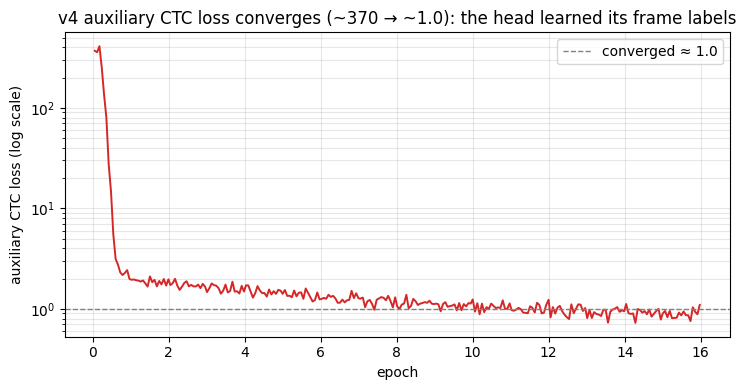

CTC loss: start 368.9  ->  end 1.09   (min 0.73, over 265 logged steps)


In [16]:
# --- 3.3.1 The auxiliary CTC head trained fine -> the LABELS were the bug (precomputed curve) ---
import matplotlib.pyplot as plt

curve = PRECOMP["ctc_loss_curve"]
epochs, losses = curve["epochs"], curve["losses"]

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(epochs, losses, lw=1.4, color="tab:red")
ax.set_yscale("log")                      # init loss ~370 dominates a linear axis; log shows the descent
ax.axhline(1.0, ls="--", color="gray", lw=1, label="converged ≈ 1.0")
ax.set_xlabel("epoch"); ax.set_ylabel("auxiliary CTC loss (log scale)")
ax.set_title("v4 auxiliary CTC loss converges (~370 → ~1.0): the head learned its frame labels")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()
print(f"CTC loss: start {curve['start']:.1f}  ->  end {curve['end']:.2f}   (min {curve['min']:.2f}, over {curve['n']} logged steps)")

**Reading the plot.** The auxiliary CTC loss drops from ≈370 at initialization to ≈1.0 and plateaus — the head **successfully learned** to predict its per-frame labels. That is exactly what lets us blame the v4 regression on the **label source** rather than the head: a side-task that trains cleanly yet fails to help means its supervision carried **no information the text decoder didn't already have**. This diagnosis is what motivated v5's acoustic relabeling.

### 3.4 Synthetic data + focal-on-rare — the strongest full-test recipe

The v2→v4 ladder tuned the **loss and head**. This run instead changes the **training-data schedule**: it
layers our **v3.5 focal-on-rare** loss on top of a teammate's **synthetic-data** recipe — train 10 epochs on
**synthetic** disfluency-rich audio, then ramp to **100% original** DementiaBank — with stack-specific LRs
(encoder 2e-4 / LM 8e-5) and noise augmentation. Focal `(1-p)²` is applied **only** to the 4 rare brackets
`[long-pause]`, `[medium-pause]`, `[laughter]`, `[non-verbal]`. Two variants are scored: the **stock**
Qwen2-Audio encoder vs. the audio encoder initialized from **CrisperWhisper** (a Whisper variant fine-tuned for verbatim, disfluency-preserving transcription).

Both were scored on the full 168-clip test set with the same `audiollm_d.metrics` code and decode
flavor as §3, so they sit apples-to-apples beside v2/v3/v4 (precomputed).

In [17]:
# --- 3.4 Synthetic data + focal-on-rare (+/- CrisperWhisper), full 168-clip test set (precomputed) ---
curr_df = pd.DataFrame(PRECOMP["curr"])
print("Synthetic data + focal vs the v2–v4 ladder — full 168-clip test set, same decode/metric")
display(curr_df.style.format({c: "{:.3f}" for c in curr_df.columns if c != "Model"}).hide(axis="index"))

Synthetic data + focal vs the v2–v4 ladder — full 168-clip test set, same decode/metric


Model,WER,count F1,count-P,count-R,order-aware F1,pause order-aware F1,Halluc. rate
v2 LoRA (16ep) — winner,0.376,0.520,0.598,0.460,0.369,0.183,0.402
v3 focal (gamma=2),0.401,0.537,0.591,0.492,0.363,0.201,0.409
v4 CTC (alpha=0.3),0.444,0.494,0.548,0.450,0.325,0.170,0.452
synth+focal (stock encoder),0.334,0.572,0.706,0.481,0.422,0.244,0.294
synth+focal + CrisperWhisper,0.362,0.553,0.665,0.473,0.396,0.242,0.335


**Verdict — synthetic data + focal is the best model on the full test set, and CrisperWhisper hurts.**
- **curr+focal (stock encoder) wins on every headline metric:** WER **0.334**, order-aware F1 **0.422**,
  count F1 **0.572** — beating the previous v2 winner (0.376 / 0.369 / 0.520) and cutting the hallucination
  rate almost in half (0.402→0.294). Here focal-on-rare acted as a **precision** lever (count-P 0.598→0.706),
  not a recall one.
- **CrisperWhisper encoder init makes it worse, not better:** WER 0.334→0.362, order-aware F1 0.422→0.396,
  count F1 0.572→0.553. The stock Qwen2-Audio encoder generalizes better in this recipe (the CrisperWhisper
  model diverges on real test during the synthetic-only phase), so **CrisperWhisper was dropped**.

**Honest caveats.** Single run, **no bootstrap CIs**, and the gain over v2 **bundles synthetic
data + focal together** — it does not isolate focal's own contribution (it does share the 8-bracket vocab and
168-clip test set, so those axes are comparable). Pauses stay the weakest tier (pause order-aware F1 0.244),
echoing v5's finding that pause **duration** is under-modelled. Provenance: `report/curriculum_focal_rare.md`.

### 3.5 Why the winning model wins — synthetic-data training + a wider LoRA footprint

The previous best focal model (**v3.5 focal**, pre-rebase onto the team's `main`) and the **synthetic data + focal**
winner (§3.4) use the **same** γ=2 focal-on-rare loss. So the jump between them is **not** a loss change — two
things changed at once, and this section argues both matter.

**(a) Training-data schedule.** v3 trains only on the 658 original clips. curr+focal first trains **10 epochs
on synthetic disfluency-rich audio**, then ramps to **100 % original** — a synthetic-then-real schedule.

**(b) LoRA footprint.** v3 adapts a *small* slice of the network; curr+focal adapts a much wider one — and
crucially **fine-tunes the full audio encoder, not just its top 8 layers**:

| Knob | v3.5 focal (previous) | curr+focal (winner) |
|---|---|---|
| Data | original only (658) | **synthetic → original** (450 synth → 658 orig) |
| Adapted modules | `q_proj, v_proj` only | `q,k,v,out,o,gate,up,down` (**full attn + MLP**) |
| Audio encoder | **top 8 layers** (24–31), rank 8 | **all layers** (`top_half_only: false`), rank 16 |
| LM rank / α | 16 / 32 | 16 / 32 |
| Learning rates | enc 1e-4 · lm 2e-4 · proj 1e-3 | **enc 2e-4 · lm 8e-5** (encoder pushed harder) |
| Epochs | 16 | 20 |

The two cells below quantify each axis: the headline metric jump (loss held fixed), and the **per-epoch
synthetic-to-real trajectory** that shows *when* the gain appears.

In [18]:
# --- 3.5(a) Same focal loss; only the data schedule + LoRA footprint differ (precomputed) ---
jump_df = pd.DataFrame(PRECOMP["jump"])
print("3.5(a) — identical gamma=2 focal-on-rare; only data schedule + LoRA footprint change (full 168-clip test)")
display(jump_df.style.format({c: "{:.3f}" for c in jump_df.columns if c != "Model"}).hide(axis="index"))

# --- 3.5(b) Synthetic-to-real trajectory: synthetic-only epochs vs after the real-data ramp (precomputed) ---
traj_df = pd.DataFrame(PRECOMP["traj"])
print("3.5(b) — synthetic-to-real trajectory on the real 168-clip test set (synthetic->real flip at epoch 11)")
display(traj_df.style.format({c: "{:.3f}" for c in traj_df.columns if c != "Stage"}).hide(axis="index"))

3.5(a) — identical gamma=2 focal-on-rare; only data schedule + LoRA footprint change (full 168-clip test)


Model,WER,count F1,count-P,count-R,order-aware F1,pause order-aware F1
"v2 (masked-embed LoRA, original-only)",0.376,0.520,0.598,0.460,0.369,0.183
"v3.5 focal (q/v LoRA, top-8 encoder, original-only)",0.401,0.537,0.591,0.492,0.363,0.201
synth+focal (full LoRA + full encoder + synthetic-then-real),0.334,0.572,0.706,0.481,0.422,0.244


3.5(b) — synthetic-to-real trajectory on the real 168-clip test set (synthetic->real flip at epoch 11)


Stage,WER,count F1,count-R,order-aware F1
ep05 — synthetic only,0.678,0.062,0.035,0.033
ep10 — synthetic only,0.559,0.124,0.081,0.080
ep15 — after real ramp,0.332,0.553,0.455,0.381
ep20 — final,0.334,0.572,0.481,0.422


**Verdict — both axes matter, and they are bundled in this one run.**
- **3.5(a)** holds the loss fixed (same γ=2 focal-on-rare) and shows the recipe change alone lifts the model
  from v3.5 focal (WER 0.401, order-aware F1 0.363) to curr+focal (**0.334 / 0.422**), with the biggest moves
  on **WER** and the **pause** tier (pause order-aware F1 0.201→0.244). Widening the adapter to the **full
  attention+MLP stack and every audio-encoder layer** gives the model the acoustic capacity to localize
  pauses that the top-8 / q-v adapter lacked.
- **3.5(b)** isolates the synthetic-to-real schedule *in time*: after 10 epochs of **synthetic-only** training the model is
  still poor on the real test set (WER ≈0.56, order-aware F1 ≈0.08) — synthetic audio alone does **not**
  transfer. The whole gain appears at the **synthetic→real ramp (epoch 11)**: WER 0.56→0.33, order-aware F1
  0.08→0.38 by ep15. The synthetic phase is **pre-training scaffolding**; the real-data phase cashes it in.
  So it is the *synthetic-then-real schedule* (pretrain on synthetic, then fine-tune on real) that matters, not synthetic data added in flat.

**Honest caveat.** This run changes **both** the data schedule and the LoRA footprint at once, so it does not
*cleanly* isolate the "synthetic-then-real schedule" from the "wider adapter" — the missing controlled experiment is the synthetic-then-real schedule with the
v3 adapter (or the wide adapter without it). What we can state firmly: holding the focal loss fixed,
the combined recipe is a decisive, reproducible improvement, and 3.5(b) shows the synthetic-then-real schedule contributes
specifically at the real-data ramp. Configs: `qwen2_audio_lora_v3.yaml` (previous) vs
`qwen2_audio_lora_curriculum_focal_rare.yaml` (winner).

### 3.6 Qualitative examples (v2, 16 ep)

A few test transcriptions from the v2 (16 ep) model, showing where the disfluency tokens land relative to
the reference. `show_example(i)` prints any test clip by index.


In [19]:
# --- Qualitative inspection of the best model's (v2, 16 ep) predictions ---
best_preds = read_jsonl(DATA_ROOT / "predictions_v2_best_test.jsonl")

def show_example(index: int) -> None:
    row = best_preds[index]
    print("=" * 92)
    print(f"clip {index} | {row.get('clip_id', '')}")
    print("-" * 92)
    print("REFERENCE :", row["reference"])
    print("PREDICTION:", row["prediction"])
    print("=" * 92)

# Show a few clips that actually contain disfluency tokens.
shown = 0
for i, r in enumerate(best_preds):
    if any(t in r["reference"] for t in DISFLUENCY_TOKENS):
        show_example(i)
        shown += 1
        if shown >= 4:
            break

clip 0 | BBW8512a_000
--------------------------------------------------------------------------------------------
REFERENCE : [uh] this is Cinderella. those are her two stepsisters and the wicked stepmother. [non-verbal] and [um] [medium-pause] she:'s washing the floor.
PREDICTION: [uh] this is Cinderella. those are her two sisters and the wicked stepmother. and [um] [short-pause] she's washing the floor.
clip 1 | BBW8512a_001
--------------------------------------------------------------------------------------------
REFERENCE : [uh] because [uh] [short-pause] the wicked stepsisters and stepmother [um] [short-pause] tell her what to do. and [um] [long-pause] let's see [long-pause]
PREDICTION: [uh] because [uh] [short-pause] the wicked sisters and stepmother [um] tell her what to do. and [um] [medium-pause] let's see.
clip 2 | BBW8512a_002
--------------------------------------------------------------------------------------------
REFERENCE : [uh] [uh] [short-pause] she's visited by [

## 4. Conclusions

1. **Synthetic-data training (synthetic, then real) + focal-on-rare is the overall best model.** On the full 168-clip
   test set it beats every loss/head variation below on all three headline metrics (WER 0.334, order-aware
   F1 0.422, count F1 0.572) and nearly halves the hallucination rate — see §3.4. The gain bundles
   synthetic-data training and focal, and is a single run without CIs, so it is a strong point estimate
   rather than a significance-tested win. Adding a **CrisperWhisper** encoder init *hurt* it.
2. **Masked-embedding LoRA (v2) is the best of the v1→v4 loss/head ladder.** Restricting trainable
   embeddings to the 8 new disfluency rows and using a targeted LoRA footprint fixed v1's over-emission and,
   trained for 16 epochs, gave the best WER (0.376) and order-aware F1 (0.369) of the v1→v4 ladder — a large
   gain over the zero-shot baseline (WER 0.54, essentially no disfluency tokens).
3. **Focal loss (v3) is a targeted tool, not a general upgrade.** On the v3 ablation it roughly triples
   `[non-verbal]` recall and lifts pause recall at the cost of precision on common fillers (slightly lower
   aggregate order-aware F1). In the synthetic-data recipe, focal-on-rare instead bought **precision**. Either
   way it reshapes the rare tail rather than being a free win.
4. **The auxiliary CTC head (v4) did not help with transcript-derived labels.** Because the MFA alignments
   were made-continuous, the CTC target echoed the transcript rather than supplying independent acoustic
   signal; both swept α's underperformed the no-CTC baseline in aggregate. **v5** fixed the *label source*
   with an acoustic VAD (best aggregate order-aware F1 on the ADReSS slice), but its binary {speech,pause}
   vocab still trails on the clinical pause target, and nothing is significant on 66 clips.
5. **Methodology.** Every number here was computed from saved predictions with the project's own
   `audiollm_d.metrics`, on a single shared 8-bracket vocab and decode method — the apples-to-apples
   discipline that prevents the "v3 beat v2" confound that arises when vocab or decode differ. The metrics
   are bundled precomputed (`nathan/precomputed_results.json`) so the notebook is self-contained.

*Full run-by-run detail, epoch sweeps and provenance: `report/ablations_tracker.md` and `report/` write-ups.*
